<a href="https://colab.research.google.com/github/varshitfauzdar/AIH_Lab_work/blob/main/labely10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

Total records: 48
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109']
Signal shape: (650000,)
Sampling frequency: 360


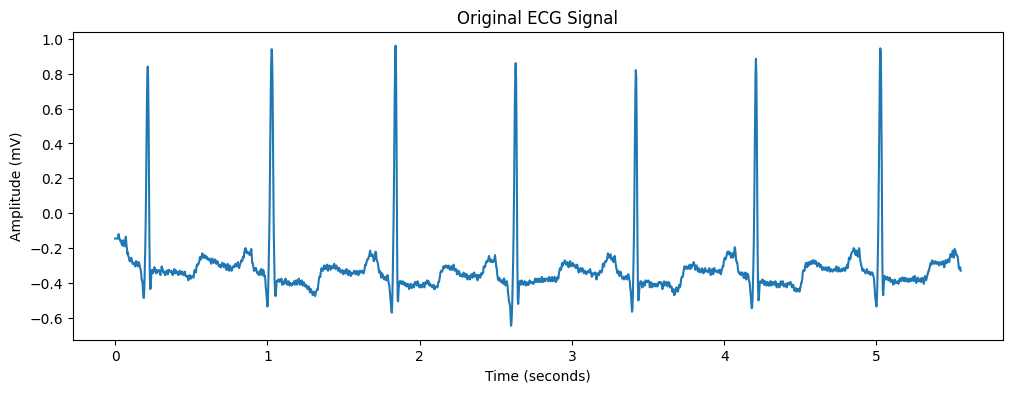

In [ ]:
path = "mitdb/1.0.0"

records = wfdb.get_record_list("mitdb")

print("Total records:", len(records))
print(records[:10])

record = wfdb.rdrecord("100", pn_dir=path)
annotation = wfdb.rdann("100", "atr", pn_dir=path)

signal = record.p_signal[:, 0]
fs = record.fs

print("Signal shape:", signal.shape)
print("Sampling frequency:", fs)

plt.figure(figsize=(12, 4))
plt.plot(np.arange(2000) / fs, signal[:2000])
plt.title("Original ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.show()

{'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0, 'A': 1, 'a': 1, 'J': 1, 'S': 1, 'V': 2, 'E': 2, 'F': 3, '/': 4, 'f': 4, 'Q': 4}


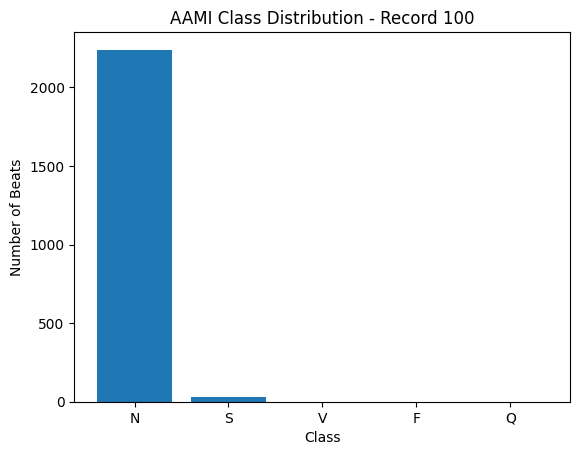

0    2239
1      33
2       1
3       0
4       0
Name: count, dtype: int64


In [ ]:
classes = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q"]
}

label_map = {
    symbol: i
    for i, symbols in enumerate(classes.values())
    for symbol in symbols
}

print(label_map)

labels = [
    label_map[s]
    for s in annotation.symbol
    if s in label_map
]

names = list(classes.keys())

counts = pd.Series(labels).value_counts().reindex(range(5), fill_value=0)

plt.bar(names, counts)
plt.title("AAMI Class Distribution - Record 100")
plt.xlabel("Class")
plt.ylabel("Number of Beats")
plt.show()

print(counts)

Records remaining: 44


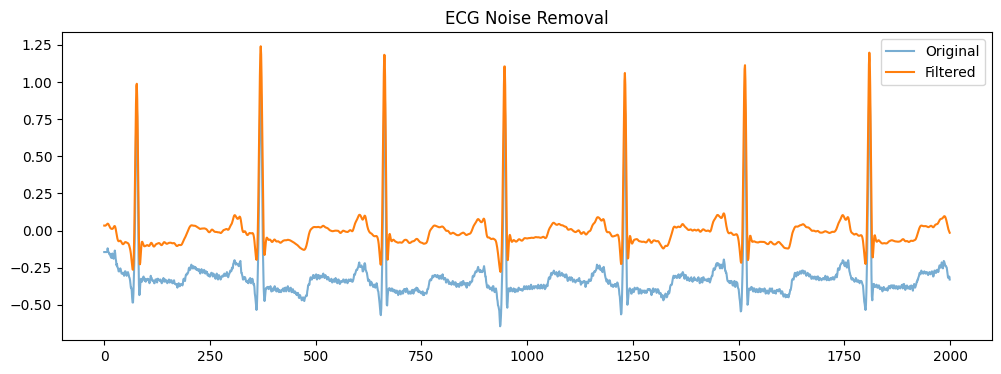

In [ ]:
paced = ["102", "104", "107", "217"]

records = [r for r in records if r not in paced]

print("Records remaining:", len(records))

def filter_ecg(signal, fs):
    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, signal)

filtered = filter_ecg(signal, fs)

plt.figure(figsize=(12, 4))
plt.plot(signal[:2000], label="Original", alpha=0.6)
plt.plot(filtered[:2000], label="Filtered")
plt.legend()
plt.title("ECG Noise Removal")
plt.show()

In [ ]:
def extract_beats(record_id):
    rec = wfdb.rdrecord(record_id, pn_dir=path)
    ann = wfdb.rdann(record_id, "atr", pn_dir=path)

    sig = filter_ecg(rec.p_signal[:, 0], rec.fs)

    X, y = [], []

    for peak, symbol in zip(ann.sample, ann.symbol):
        if symbol not in label_map:
            continue

        start = peak - 180
        end = peak + 180

        if start < 0 or end > len(sig):
            continue

        beat = sig[start:end]
        X.append(beat)
        y.append(label_map[symbol])

    return np.array(X), np.array(y)

X_list, y_list, groups = [], [], []

for record_id in records:
    x, y = extract_beats(record_id)

    if len(x) == 0:
        continue

    X_list.append(x)
    y_list.append(y)
    groups.extend([record_id] * len(y))

X = np.concatenate(X_list)
y = np.concatenate(y_list)
groups = np.array(groups)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100682, 360)
y shape: (100682,)


In [ ]:
train_records, temp_records = train_test_split(
    np.unique(groups), test_size=0.30, random_state=42
)

val_records, test_records = train_test_split(
    temp_records, test_size=0.50, random_state=42
)

train_mask = np.isin(groups, train_records)
val_mask = np.isin(groups, val_records)
test_mask = np.isin(groups, test_records)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(X_train.shape, X_val.shape, X_test.shape)

(68508, 360) (15768, 360) (16406, 360)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train = X_train.reshape(-1, 360, 1)
X_val = X_val.reshape(-1, 360, 1)
X_test = X_test.reshape(-1, 360, 1)

print(X_train.shape)
present = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=present,
    y=y_train
)

class_weights = dict(zip(present, weights))

print(class_weights)

(68508, 360, 1)
{np.int64(0): np.float64(0.22604678787078894), np.int64(1): np.float64(7.299733617474693), np.int64(2): np.float64(2.6148091603053434), np.int64(3): np.float64(17.817425227568272), np.int64(4): np.float64(1712.7)}


In [ ]:
def build_model(model_type):
    model = Sequential()
    model.add(Input(shape=(360, 1)))

    if model_type == "RNN":
        model.add(SimpleRNN(32))
    elif model_type == "LSTM":
        model.add(LSTM(32))
    else:
        model.add(GRU(32))

    model.add(Dropout(0.3))
    model.add(Dense(32, activation="relu"))
    model.add(Dense(5, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
models = {}
histories = {}

for name in ["RNN", "LSTM", "GRU"]:
    print("Training:", name)

    model = build_model(name)

    early = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=128,
        class_weight=class_weights,
        callbacks=[early],
        verbose=1
    )

    models[name] = model
    histories[name] = history

Training: RNN
Epoch 1/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 57s 90ms/step - accuracy: 0.3260 - loss: 1.6489 - val_accuracy: 0.4857 - val_loss: 1.4308
Epoch 2/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 34s 63ms/step - accuracy: 0.2203 - loss: 1.5158 - val_accuracy: 0.0408 - val_loss: 1.6338
Epoch 3/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 32s 60ms/step - accuracy: 0.2333 - loss: 1.5322 - val_accuracy: 0.2650 - val_loss: 1.5973
Epoch 4/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 32s 59ms/step - accuracy: 0.1704 - loss: 1.5050 - val_accuracy: 0.0661 - val_loss: 1.6346
Training: LSTM
Epoch 1/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 93s 170ms/step - accuracy: 0.4731 - loss: 1.6023 - val_accuracy: 0.0266 - val_loss: 1.4785
Epoch 2/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 140s 167ms/step - accuracy: 0.1136 - loss: 1.4637 - val_accuracy: 0.1470 - val_loss: 1.4549
Epoch 3/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 92s 171ms/step - accuracy: 0.1254 - loss: 1.3719 - val_accuracy: 0.2164 - val_loss: 1.4790
Epoch 4/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 90s 167ms/step - 

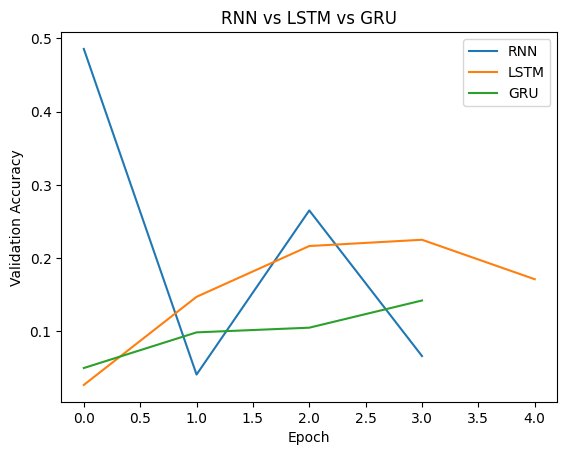

513/513 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step
513/513 ━━━━━━━━━━━━━━━━━━━━ 17s 33ms/step
513/513 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step
  Model  Accuracy  Precision    Recall        F1
0   RNN  0.307875   0.183759  0.132356  0.110153
1  LSTM  0.031818   0.139944  0.141371  0.030160
2   GRU  0.070157   0.198861  0.190296  0.028355


In [ ]:
for name, history in histories.items():
    plt.plot(history.history["val_accuracy"], label=name)

plt.title("RNN vs LSTM vs GRU")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    pred = np.argmax(model.predict(X_test), axis=1)

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="macro", zero_division=0),
        recall_score(y_test, pred, average="macro", zero_division=0),
        f1_score(y_test, pred, average="macro", zero_division=0)
    ])

df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

print(df)

513/513 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step


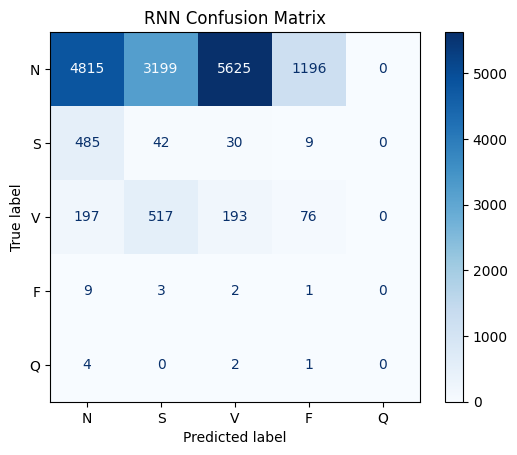

513/513 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step


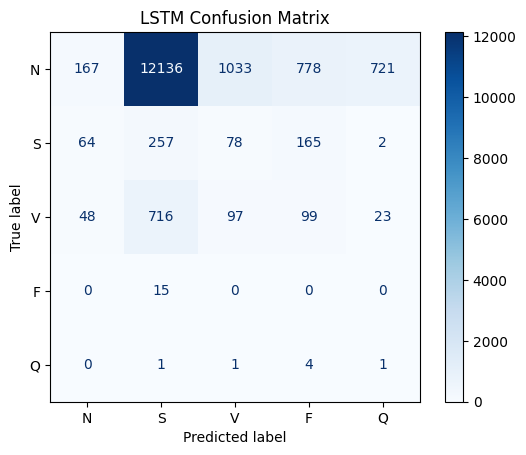

513/513 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step


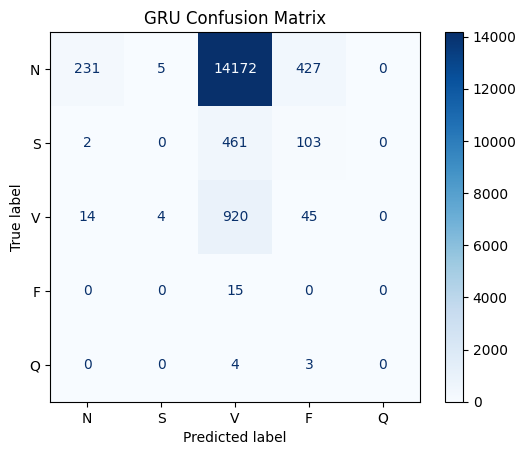

513/513 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step

 RNN
              precision    recall  f1-score   support

           N       0.87      0.32      0.47     14835
           S       0.01      0.07      0.02       566
           V       0.03      0.20      0.06       983
           F       0.00      0.07      0.00        15
           Q       0.00      0.00      0.00         7

    accuracy                           0.31     16406
   macro avg       0.18      0.13      0.11     16406
weighted avg       0.79      0.31      0.43     16406

513/513 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step

 LSTM
              precision    recall  f1-score   support

           N       0.60      0.01      0.02     14835
           S       0.02      0.45      0.04       566
           V       0.08      0.10      0.09       983
           F       0.00      0.00      0.00        15
           Q       0.00      0.14      0.00         7

    accuracy                           0.03     16406
   macro avg       0.14      0.14

In [ ]:
for name, model in models.items():
    pred = np.argmax(model.predict(X_test), axis=1)

    cm = confusion_matrix(y_test, pred, labels=range(5))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=names
    ).plot(cmap="Blues")

    plt.title(name + " Confusion Matrix")
    plt.show()

for name, model in models.items():
    pred = np.argmax(model.predict(X_test), axis=1)

    print("\n", name)
    print(classification_report(
        y_test,
        pred,
        labels=range(5),
        target_names=names,
        zero_division=0
    ))

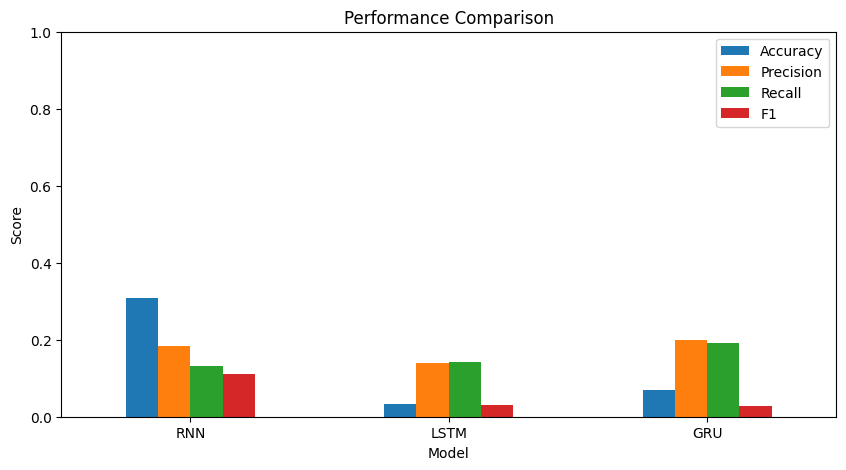

Best Model: RNN
Accuracy: 0.30787516762160183
F1 Score: 0.11015256454491815


In [ ]:
df.set_index("Model").plot(kind="bar", figsize=(10, 5))

plt.title("Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

best = df.loc[df["F1"].idxmax()]

print("Best Model:", best["Model"])
print("Accuracy:", best["Accuracy"])
print("F1 Score:", best["F1"])